# Q1

In [ ]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OrdinalEncoder
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
import copy
import json

In [9]:
def calculate_entropy(y):
    """محاسبه آنتروپی برای یک آرایه یا سری پانداس"""
    counts = y.value_counts()
    probabilities = counts / len(y)
    entropy = -np.sum(probabilities * np.log2(probabilities))
    return entropy

def calculate_information_gain(data, feature, target):
    """محاسبه بهره اطلاعات (Information Gain) برای یک ویژگی خاص"""
    parent_entropy = calculate_entropy(data[target])
    
    weighted_child_entropy = 0
    unique_values = data[feature].unique()
    
    for value in unique_values:
        subset = data[data[feature] == value]
        if len(subset) == 0:
            continue
        weight = len(subset) / len(data)
        subset_entropy = calculate_entropy(subset[target])
        weighted_child_entropy += weight * subset_entropy
        
    information_gain = parent_entropy - weighted_child_entropy
    return information_gain

def find_best_feature(data, features, target):
    """پیدا کردن بهترین ویژگی بر اساس بیشترین بهره اطلاعات"""
    best_gain = -1
    best_feature = None
    
    for feature in features:
        gain = calculate_information_gain(data, feature, target)
        if gain > best_gain:
            best_gain = gain
            best_feature = feature
            
    return best_feature

class Node:
    """کلاس گره (Node) برای ساخت درخت تصمیم جهت هرس"""
    def __init__(self, feature=None, label=None, majority_class=None):
        self.feature = feature        # ویژگی که بر اساس آن تقسیم انجام می‌شود
        self.label = label            # برچسب کلاس (اگر گره برگ باشد)
        self.majority_class = majority_class # کلاس غالب در این گره (برای هرس لازم است)
        self.branches = {}            # شاخه‌ها (گره‌های فرزند)
        
    def is_leaf(self):
        """بررسی اینکه آیا گره، برگ است یا خیر"""
        return self.label is not None

def build_tree_scratch(data, parent_data, features, target):
    """
    ساخت بازگشتی درخت تصمیم ID3 با استفاده از کلاس Node
    """
    
    # حالت پایه ۱: اگر دیتاست خالی است، کلاس غالب والد را برگردان
    if len(data) == 0:
        maj_class = parent_data[target].mode()[0]
        return Node(label=maj_class, majority_class=maj_class)

    # کلاس غالب داده‌های فعلی (برای هرس و پیش‌بینی استفاده می‌شود)
    majority_class = data[target].mode()[0]
    
    # حالت پایه ۲: اگر همه برچسب‌ها یکسان هستند (گره خالص)
    if len(data[target].unique()) == 1:
        return Node(label=majority_class, majority_class=majority_class)
    
    # حالت پایه ۳: اگر ویژگی دیگری برای تقسیم وجود ندارد
    if len(features) == 0:
        return Node(label=majority_class, majority_class=majority_class)
    
    # ۱. پیدا کردن بهترین ویژگی
    best_feature = find_best_feature(data, features, target)
    
    # حالت پایه ۴: اگر هیچ ویژگی بهره اطلاعات مثبت ندهد
    if best_feature is None:
        return Node(label=majority_class, majority_class=majority_class)
    
    # ۲. ساخت گره داخلی
    node = Node(feature=best_feature, majority_class=majority_class)
    
    # ۳. حذف ویژگی استفاده شده از لیست ویژگی‌های باقیمانده
    remaining_features = [f for f in features if f != best_feature]
    
    # ۴. ساخت زیردرخت‌ها به صورت بازگشتی
    for value in data[best_feature].unique():
        subset_data = data[data[best_feature] == value]
        subtree = build_tree_scratch(subset_data, data, remaining_features, target)
        node.branches[value] = subtree
        
    return node

def predict_single_scratch(sample, node):
    """پیش‌بینی کلاس برای یک نمونه تکی با استفاده از درخت ساخته شده"""
    if node.is_leaf():
        return node.label
    
    sample_value = sample[node.feature]
    
    if sample_value not in node.branches:
        # اگر مقداری در داده تست بود که در داده آموزش نبود، کلاس غالب گره فعلی را برگردان
        return node.majority_class
    
    next_node = node.branches[sample_value]
    return predict_single_scratch(sample, next_node)

def predict_batch_scratch(data, tree):
    """پیش‌بینی برای کل دیتافریم"""
    return data.apply(predict_single_scratch, args=(tree,), axis=1)

# --- توابع هرس (Pruning) ---

def calculate_model_accuracy(tree, data, target):
    """محاسبه دقت مدل بر روی داده‌های اعتبارسنجی"""
    X_data = data.drop(target, axis=1)
    y_true = data[target]
    y_pred = predict_batch_scratch(X_data, tree)
    return accuracy_score(y_true, y_pred)

def count_nodes(node):
    """شمارش تعداد کل گره‌های درخت"""
    if node.is_leaf():
        return 1
    count = 1
    for child in node.branches.values():
        count += count_nodes(child)
    return count

def _prune_recursive(node, root, val_df, target):
    """تابع بازگشتی برای هرس از پایین به بالا (Reduced Error Pruning)"""
    # ۱. اگر برگ است، قابل هرس نیست
    if node.is_leaf():
        return node

    # ۲. ابتدا فرزندان را هرس کن
    for value, child_node in node.branches.items():
        node.branches[value] = _prune_recursive(child_node, root, val_df, target)
        
    # ۳. بررسی کن که آیا با هرس فرزندان، گره فعلی به برگ تبدیل شده
    if all(child.is_leaf() for child in node.branches.values()):
        # اگر همه فرزندان برگ هستند، این گره کاندید هرس است
        pass
    else:
        # اگر حداقل یک فرزند گره داخلی باشد، این گره را نمی‌توان هرس کرد
         if node.is_leaf():
            return node


    # ۴. بررسی هرس گره فعلی
    # دقت کل درخت را *قبل* از هرس این گره محاسبه کن
    acc_before = calculate_model_accuracy(root, val_df, target)
    
    # ۵. گره را به طور موقت به برگ تبدیل کن (با کلاس غالب)
    original_feature = node.feature
    original_branches = node.branches
    original_label = node.label
    
    node.feature = None
    node.branches = {}
    node.label = node.majority_class  # تبدیل به برگ
    
    # ۶. دقت کل درخت را *بعد* از هرس محاسبه کن
    acc_after = calculate_model_accuracy(root, val_df, target)
    
    # ۷. مقایسه دقت‌ها
    if acc_after >= acc_before:
        # اگر دقت بهبود یافت (یا مساوی بود)، هرس را نگه دار
        return node
    else:
        # در غیر این صورت، گره را به حالت قبل برگردان
        node.feature = original_feature
        node.branches = original_branches
        node.label = original_label
        return node

def prune_tree(root, val_df, target):
    """
    تابع اصلی هرس. فرآیند هرس بازگشتی را تا زمانی که دیگر بهبودی حاصل نشود، تکرار می‌کند.
    """
    iteration = 1
    while True:
        nodes_before = count_nodes(root)
        print(f"تکرار هرس {iteration}: شروع با {nodes_before} گره...")
        
        # یک دور کامل هرس از پایین به بالا
        root = _prune_recursive(root, root, val_df, target)
        
        nodes_after = count_nodes(root)
        
        if nodes_before == nodes_after:
            print(f"هرس کامل شد. تعداد گره نهایی: {nodes_after}")
            break
        iteration += 1
    return root

# --- تابع کمکی برای رسم ماتریس اغتشاش ---
def plot_confusion_matrix(y_true, y_pred, labels, title):
    """رسم ماتریس اغتشاش با استفاده از Seaborn"""
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.ylabel('Actual Class')
    plt.xlabel('Predicted Class')
    plt.show()


--- سوال ۱ (الف): بارگیری داده Car Evaluation ---

تعداد کل نمونه‌ها: 1728
تعداد نمونه‌های آموزش (80%): 1382
تعداد نمونه‌های آزمون (20%): 346

--- در حال آموزش درخت ID3 (بخش الف)... ---
آموزش کامل شد. تعداد گره‌ها: 349

--- ارزیابی مدل بخش الف روی داده‌های آزمون... ---

--- نتایج سوال ۱ (الف) ---
Accuracy (80/20 split): 92.49%

Confusion Matrix (80/20 split):


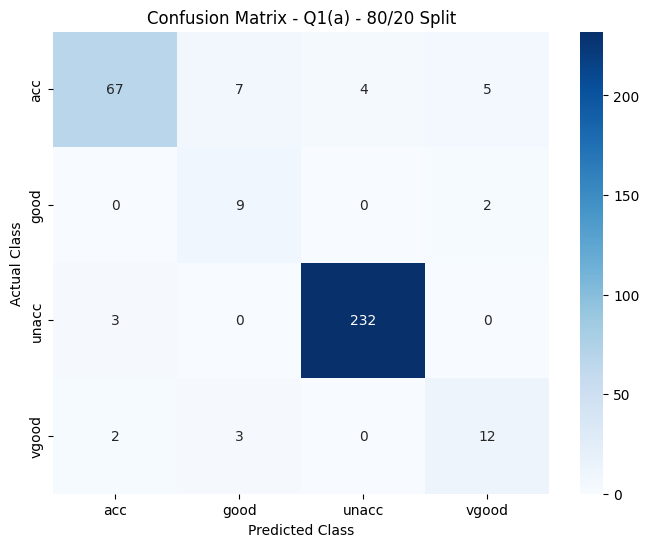

In [ ]:

print("--- سوال ۱ (الف): بارگیری داده Car Evaluation ---")
url_car = "https://archive.ics.uci.edu/ml/machine-learning-databases/car/car.data"
column_names_car = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']
df_car = pd.read_csv(url_car, header=None, names=column_names_car)

TARGET_CAR = 'class'
FEATURES_CAR = df_car.columns.drop(TARGET_CAR).tolist()
LABELS_CAR = sorted(df_car[TARGET_CAR].unique())

# ۱. تقسیم داده‌ها به نسبت ۸۰٪ آموزش و ۲۰٪ آزمون
train_df_car_a, test_df_car_a = train_test_split(df_car, test_size=0.20, random_state=42)

print(f"\nتعداد کل نمونه‌ها: {len(df_car)}")
print(f"تعداد نمونه‌های آموزش (80%): {len(train_df_car_a)}")
print(f"تعداد نمونه‌های آزمون (20%): {len(test_df_car_a)}")

# ۲. آموزش مدل ID3
print("\n--- در حال آموزش درخت ID3 (بخش الف)... ---")
# از دیتافریم آموزش هم به عنوان داده اصلی و هم داده والد (برای حالت پایه) استفاده می‌کنیم
tree_car_a = build_tree_scratch(train_df_car_a, train_df_car_a, FEATURES_CAR, TARGET_CAR)
print(f"آموزش کامل شد. تعداد گره‌ها: {count_nodes(tree_car_a)}")

# ۳. ارزیابی مدل
print("\n--- ارزیابی مدل بخش الف روی داده‌های آزمون... ---")
X_test_car_a = test_df_car_a[FEATURES_CAR]
y_test_car_a = test_df_car_a[TARGET_CAR]

y_pred_car_a = predict_batch_scratch(X_test_car_a, tree_car_a)

# ۴. گزارش نتایج
accuracy_car_a = accuracy_score(y_test_car_a, y_pred_car_a)
print(f"\n--- نتایج سوال ۱ (الف) ---")
print(f"Accuracy (80/20 split): {accuracy_car_a * 100:.2f}%")

print("\nConfusion Matrix (80/20 split):")
plot_confusion_matrix(y_test_car_a, y_pred_car_a, LABELS_CAR, "Confusion Matrix - Q1(a) - 80/20 Split")


--- سوال ۱ (ب): تقسیم داده (70/10/20) ---
تعداد نمونه‌های آموزش (70%): 1209
تعداد نمونه‌های اعتبارسنجی (10%): 173
تعداد نمونه‌های آزمون (20%): 346

--- در حال آموزش درخت کامل (بخش ب)... ---
آموزش کامل شد. تعداد گره‌های درخت کامل: 314

--- در حال هرس کردن درخت با داده‌های اعتبارسنجی... ---
تکرار هرس 1: شروع با 314 گره...
تکرار هرس 2: شروع با 102 گره...
هرس کامل شد. تعداد گره نهایی: 102

--- ارزیابی مدل‌های بخش ب روی داده‌های آزمون... ---

--- نتایج سوال ۱ (ب) ---
Accuracy (Full Tree, trained on 70%): 90.17% (Nodes: 314)
Accuracy (Pruned Tree, pruned on 10%): 86.13% (Nodes: 102)

--- مقایسه با بخش (الف) ---
Accuracy (Part A, trained on 80%): 92.49% (Nodes: 349)

Confusion Matrix (Pruned Model - Q1(b)):


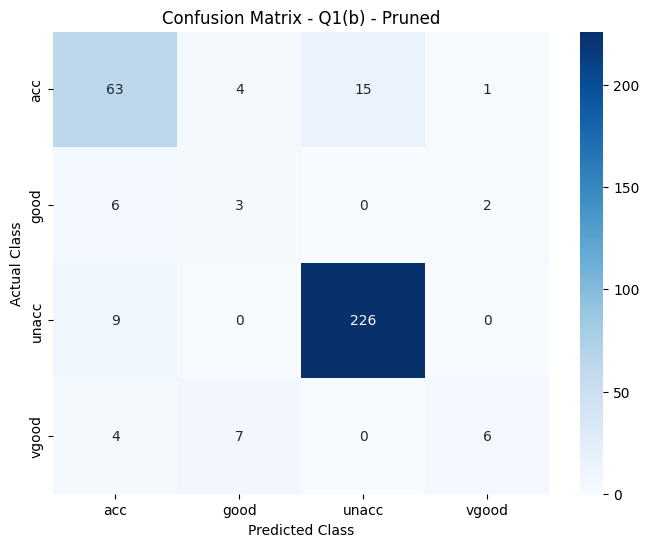

In [ ]:

print("--- سوال ۱ (ب): تقسیم داده (70/10/20) ---")

# ۱. تقسیم داده‌ها
# ابتدا به ۸۰٪ (آموزش + اعتبارسنجی) و ۲۰٪ (آزمون)
train_val_df_car_b, test_df_car_b = train_test_split(df_car, test_size=0.20, random_state=42)
# سپس ۸۰٪ را به ۷۰٪ (آموزش) و ۱۰٪ (اعتبارسنجی)
# 0.10 / 0.80 = 0.125
train_df_car_b, val_df_car_b = train_test_split(train_val_df_car_b, test_size=0.125, random_state=42)

print(f"تعداد نمونه‌های آموزش (70%): {len(train_df_car_b)}")
print(f"تعداد نمونه‌های اعتبارسنجی (10%): {len(val_df_car_b)}")
print(f"تعداد نمونه‌های آزمون (20%): {len(test_df_car_b)}")

# ۲. آموزش درخت کامل (Unpruned)
print("\n--- در حال آموزش درخت کامل (بخش ب)... ---")
full_tree_car_b = build_tree_scratch(train_df_car_b, train_df_car_b, FEATURES_CAR, TARGET_CAR)
print(f"آموزش کامل شد. تعداد گره‌های درخت کامل: {count_nodes(full_tree_car_b)}")

# ۳. هرس کردن درخت (Pruning)
print("\n--- در حال هرس کردن درخت با داده‌های اعتبارسنجی... ---")
# یک کپی عمیق از درخت کامل می‌سازیم تا درخت اصلی حفظ شود
pruned_tree_car_b = copy.deepcopy(full_tree_car_b)
pruned_tree_car_b = prune_tree(pruned_tree_car_b, val_df_car_b, TARGET_CAR)

# ۴. ارزیابی هر دو مدل (هرس‌شده و هرس‌نشده) روی داده‌های آزمون
print("\n--- ارزیابی مدل‌های بخش ب روی داده‌های آزمون... ---")
X_test_car_b = test_df_car_b[FEATURES_CAR]
y_test_car_b = test_df_car_b[TARGET_CAR]

# ارزیابی مدل کامل (هرس‌نشده)
y_pred_full_b = predict_batch_scratch(X_test_car_b, full_tree_car_b)
accuracy_full_b = accuracy_score(y_test_car_b, y_pred_full_b)

# ارزیابی مدل هرس‌شده
y_pred_pruned_b = predict_batch_scratch(X_test_car_b, pruned_tree_car_b)
accuracy_pruned_b = accuracy_score(y_test_car_b, y_pred_pruned_b)

# ۵. گزارش و مقایسه نتایج
print(f"\n--- نتایج سوال ۱ (ب) ---")
print(f"Accuracy (Full Tree, trained on 70%): {accuracy_full_b * 100:.2f}% (Nodes: {count_nodes(full_tree_car_b)})")
print(f"Accuracy (Pruned Tree, pruned on 10%): {accuracy_pruned_b * 100:.2f}% (Nodes: {count_nodes(pruned_tree_car_b)})")

print(f"\n--- مقایسه با بخش (الف) ---")
print(f"Accuracy (Part A, trained on 80%): {accuracy_car_a * 100:.2f}% (Nodes: {count_nodes(tree_car_a)})")

print("\nConfusion Matrix (Pruned Model - Q1(b)):")
plot_confusion_matrix(y_test_car_b, y_pred_pruned_b, LABELS_CAR, "Confusion Matrix - Q1(b) - Pruned")


# Q2

In [14]:
# ------------------------------------------------------------------
# سلول ۵: سوال ۲ (الف) - پیاده‌سازی از ابتدا
# ------------------------------------------------------------------

print("--- سوال ۲ (الف): بارگیری داده Nursery ---")
url_nursery = "https://archive.ics.uci.edu/ml/machine-learning-databases/nursery/nursery.data"
column_names_nursery = [
    'parents', 'has_nurs', 'form', 'children', 'housing',
    'finance', 'social', 'health', 'class'
]
df_nursery = pd.read_csv(url_nursery, header=None, names=column_names_nursery)

TARGET_NURSERY = 'class'
FEATURES_NURSERY = df_nursery.columns.drop(TARGET_NURSERY).tolist()
LABELS_NURSERY = sorted(df_nursery[TARGET_NURSERY].unique())

print(f"تعداد کل نمونه‌ها: {len(df_nursery)}")

# ۱. تعریف نسبت‌های تقسیم
split_ratios = [0.20, 0.40, 0.60] # درصد داده‌های آزمون
results_summary_q2a = []

for test_size in split_ratios:
    train_size_percent = int((1 - test_size) * 100)
    test_size_percent = int(test_size * 100)
    split_name = f"{train_size_percent}/{test_size_percent}"
    
    print(f"\n\n--- آزمایش تقسیم {split_name} ---")
    
    # ۲. تقسیم داده
    train_df, test_df = train_test_split(df_nursery, test_size=test_size, random_state=42)
    
    # ۳. آموزش مدل
    print(f"در حال آموزش مدل {split_name}...")
    tree_q2a = build_tree_scratch(train_df, train_df, FEATURES_NURSERY, TARGET_NURSERY)
    nodes = count_nodes(tree_q2a)
    print(f"آموزش کامل شد. تعداد گره‌ها: {nodes}")
    
    # ۴. ارزیابی
    X_test = test_df[FEATURES_NURSERY]
    y_test = test_df[TARGET_NURSERY]
    y_pred = predict_batch_scratch(X_test, tree_q2a)
    accuracy = accuracy_score(y_test, y_pred)
    
    print(f"Accuracy (Split {split_name}): {accuracy * 100:.2f}%")
    
    results_summary_q2a.append({
        'Split (Train/Test)': split_name,
        'Accuracy': f"{accuracy * 100:.2f}%",
        'Tree Nodes': nodes
    })
    
    # رسم ماتریس اغتشاش (به دلیل بزرگ بودن ممکن است شلوغ باشد)
    # plot_confusion_matrix(y_test, y_pred, LABELS_NURSERY, f"Confusion Matrix - Q2(a) - {split_name} Split")


# ۵. نمایش خلاصه نتایج
print("\n\n" + "="*50)
print("--- خلاصه نتایج سوال ۲ (الف) ---")
print("="*50)
summary_df_q2a = pd.DataFrame(results_summary_q2a)
print(summary_df_q2a.to_string(index=False))

# ذخیره بهترین نتیجه برای مقایسه در بخش (ب)
best_accuracy_q2a_str = summary_df_q2a.iloc[summary_df_q2a['Accuracy'].str.replace('%', '').astype(float).idxmax()]['Accuracy']
best_accuracy_q2a = float(best_accuracy_q2a_str.replace('%', ''))


--- سوال ۲ (الف): بارگیری داده Nursery ---
تعداد کل نمونه‌ها: 12960


--- آزمایش تقسیم 80/20 ---
در حال آموزش مدل 80/20...
آموزش کامل شد. تعداد گره‌ها: 1047
Accuracy (Split 80/20): 98.34%


--- آزمایش تقسیم 60/40 ---
در حال آموزش مدل 60/40...
آموزش کامل شد. تعداد گره‌ها: 945
Accuracy (Split 60/40): 97.38%


--- آزمایش تقسیم 40/60 ---
در حال آموزش مدل 40/60...
آموزش کامل شد. تعداد گره‌ها: 766
Accuracy (Split 40/60): 96.26%


--- خلاصه نتایج سوال ۲ (الف) ---
Split (Train/Test) Accuracy  Tree Nodes
             80/20   98.34%        1047
             60/40   97.38%         945
             40/60   96.26%         766


--- سوال ۲ (ب): تنظیم هایپرپارامتر با GridSearchCV ---

در حال اجرای Grid Search با 5-fold Cross-Validation...
Fitting 5 folds for each of 144 candidates, totalling 720 fits
Grid Search کامل شد.

--- نتایج سوال ۲ (ب) ---
بهترین هایپرپارامترهای یافت شده:
{'ccp_alpha': 0.0, 'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2}

بهترین دقت (Best CV Accuracy) با (k=5): 99.54%

--- مقایسه نهایی بخش (الف) و (ب) ---
بهترین دقت بخش (الف) (پیاده‌سازی از ابتدا، 80/20): 98.34%
بهترین دقت بخش (ب) (Sklearn, 5-Fold CV):      99.54%

نتیجه: مدل تنظیم‌شده با Cross-Validation (بخش ب) عملکرد بهتری نسبت به بهترین حالت بخش (الف) داشت.

--- ارزیابی نهایی بهترین مدل یافت‌شده روی داده تست (80/20) ---
دقت نهایی بهترین مدل روی 20% داده تست: 99.50%


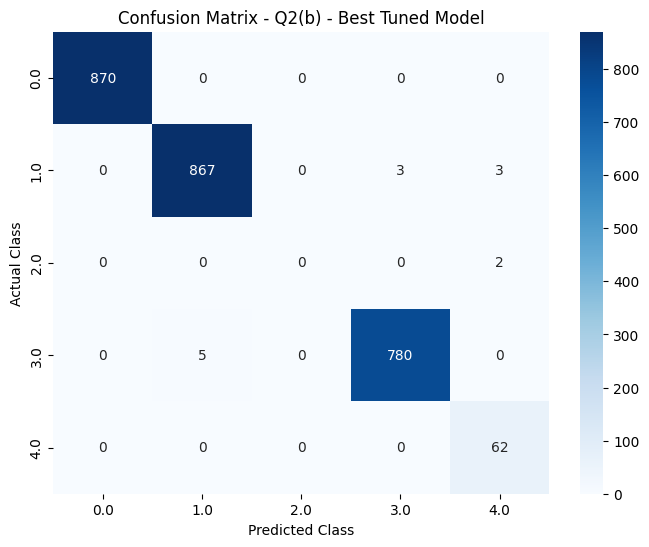

توجه: برچسب‌های ماتریس اغتشاش به دلیل انکودینگ عددی هستند.
 (0=not_recom, 1=priority, 2=recommend, ...)


In [15]:

print("--- سوال ۲ (ب): تنظیم هایپرپارامتر با GridSearchCV ---")

# ۱. پیش‌پردازش: تبدیل داده‌های رشته‌ای به عددی
# Scikit-learn برخلاف پیاده‌سازی از ابتدا، نیاز به داده‌های عددی دارد
encoder = OrdinalEncoder()
df_nursery_encoded = pd.DataFrame(
    encoder.fit_transform(df_nursery),
    columns=df_nursery.columns
)

X = df_nursery_encoded[FEATURES_NURSERY]
y = df_nursery_encoded[TARGET_NURSERY]

# برچسب‌های اصلی (رشته‌ای) برای رسم ماتریس نهایی
LABELS_NURSERY_ORIGINAL = encoder.categories_[df_nursery.columns.get_loc(TARGET_NURSERY)]
LABELS_NURSERY_ENCODED = sorted(y.unique())


# ۲. تعریف شبکه پارامترها (Hyperparameter Grid)
# مطابق با موارد خواسته شده در PDF
param_grid = {
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5],
    'ccp_alpha': [0.0, 0.001, 0.005, 0.01]  # پارامتر هرس
}

# ۳. تعریف مدل پایه
# از 'entropy' استفاده می‌کنیم تا معادل ID3 (مبتنی بر بهره اطلاعات) باشد
dt_classifier = DecisionTreeClassifier(criterion='entropy', random_state=42)

# ۴. تعریف K-Fold (k=5)
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)

# ۵. تعریف و اجرای GridSearchCV
grid_search = GridSearchCV(
    estimator=dt_classifier,
    param_grid=param_grid,
    cv=kf,
    scoring='accuracy',
    n_jobs=-1,  # استفاده از تمام هسته‌های CPU
    verbose=1   # نمایش پیشرفت
)

print(f"\nدر حال اجرای Grid Search با {k}-fold Cross-Validation...")
# این مرحله ممکن است کمی زمان ببرد
grid_search.fit(X, y)
print("Grid Search کامل شد.")

# ۶. گزارش بهترین نتایج
best_params_q2b = grid_search.best_params_
best_score_q2b = grid_search.best_score_

print("\n" + "="*50)
print("--- نتایج سوال ۲ (ب) ---")
print("="*50)
print(f"بهترین هایپرپارامترهای یافت شده:")
print(best_params_q2b)
print(f"\nبهترین دقت (Best CV Accuracy) با (k=5): {best_score_q2b * 100:.2f}%")

# ۷. مقایسه نهایی
print("\n" + "="*50)
print("--- مقایسه نهایی بخش (الف) و (ب) ---")
print("="*50)
print(f"بهترین دقت بخش (الف) (پیاده‌سازی از ابتدا، 80/20): {best_accuracy_q2a:.2f}%")
print(f"بهترین دقت بخش (ب) (Sklearn, 5-Fold CV):      {best_score_q2b * 100:.2f}%")

if best_score_q2b * 100 > best_accuracy_q2a:
    print("\nنتیجه: مدل تنظیم‌شده با Cross-Validation (بخش ب) عملکرد بهتری نسبت به بهترین حالت بخش (الف) داشت.")
else:
    print("\nنتیجه: مدل پیاده‌سازی شده از ابتدا (بخش الف) عملکرد بهتری نسبت به مدل تنظیم‌شده (بخش ب) داشت.")

# ۸. (اختیاری) ارزیابی نهایی بهترین مدل روی یک داده تست مجزا
print("\n--- ارزیابی نهایی بهترین مدل یافت‌شده روی داده تست (80/20) ---")
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(X, y, test_size=0.20, random_state=42)
final_model = DecisionTreeClassifier(criterion='entropy', random_state=42, **best_params_q2b)
final_model.fit(X_train_final, y_train_final)
y_pred_final = final_model.predict(X_test_final)
final_test_acc = accuracy_score(y_test_final, y_pred_final)

print(f"دقت نهایی بهترین مدل روی 20% داده تست: {final_test_acc * 100:.2f}%")
plot_confusion_matrix(y_test_final, y_pred_final, LABELS_NURSERY_ENCODED, f"Confusion Matrix - Q2(b) - Best Tuned Model")
print("توجه: برچسب‌های ماتریس اغتشاش به دلیل انکودینگ عددی هستند.")
print(f" (0={LABELS_NURSERY_ORIGINAL[0]}, 1={LABELS_NURSERY_ORIGINAL[1]}, 2={LABELS_NURSERY_ORIGINAL[2]}, ...)")
